# Run 4: a ten-day data gap in the wavelet analysis

Run 2's series (true sky envelope $M_c^2(t)$, seed 2026, 30 d) with a **hard gap from day 10.0 to 20.0**, a third of the
window: the series is set to zero there, and the wavelet likelihood leaves out every 10-h time pixel that overlaps the
gap plus one buffer pixel on each side (as in run 3, [gap_check.py](gap_check.py)). Everything else (priors, sampler
settings, seeds) is as in run 2, so **the only difference from run 2's wavelet run is the gap**. Unlike the 1-day gap
of run 3, 10 days is a sizeable fraction of the envelope's time scale, so the atoms have to bridge real structure.

Compared quantity for the modulation, as in run 3: the **galactic brightness recovered / injected** (amplitude ×
spectral shape × $P_c(t)$ of each posterior sample divided by the injected one). No burn-in K trace for this run.

Set `RERUN = True` to sample again (`python injection.py --tag run4 --injection sky --gap 10 20`, about 30 min).

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import corner
import jax
import jax.numpy as jnp

ROOT = Path.cwd()
while not (ROOT / 'pyproject.toml').exists():
    ROOT = ROOT.parent
HERE = ROOT / 'data' / 'wavelet_injection'
sys.path.insert(0, str(HERE))
import injection as I
import diagnostics as D
from bahamas.wavelet.model import DAY
from bahamas.wavelet.sampler import modulation_draws, _sampled
from bahamas.wavelet.simulate import power_modulation

RERUN = False
GAP = (10.0, 20.0)
CFG3 = I.with_gap(GAP, buffer_pixels=1)
OUT = HERE / 'outputs' / 'run4'
CH = ['A', 'E']
C_TRUTH, C_NOGAP, C_NOGAP_L, C_GAP, C_GAP_L, C_MUTED = '#0b0b0b', '#2a78d6', '#86b6ef', '#eb6834', '#f5b48f', '#52514e'
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25, 'axes.spines.top': False,
                     'axes.spines.right': False, 'lines.linewidth': 1.5, 'legend.frameon': False})
amp_true, amp_ref = I.true_amp(), I.load_reference()['amp']

2026-10-17 09:28:57,591 - BAHAMAS - INFO - Using JAX backend.


2026-10-17 09:28:57,592 - BAHAMAS - INFO - np is from: jax.numpy


## 1. Data and the pixels the likelihood leaves out

run 4 series = run 2 series outside the gap: True; zero inside: True
left out: time pixels [23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49] = 9.38-20.62 d (270 h)
likelihood blocks: run 2 34, run 4 21; pixels used: run 2 283016, run 4 170642 (39.7% fewer)


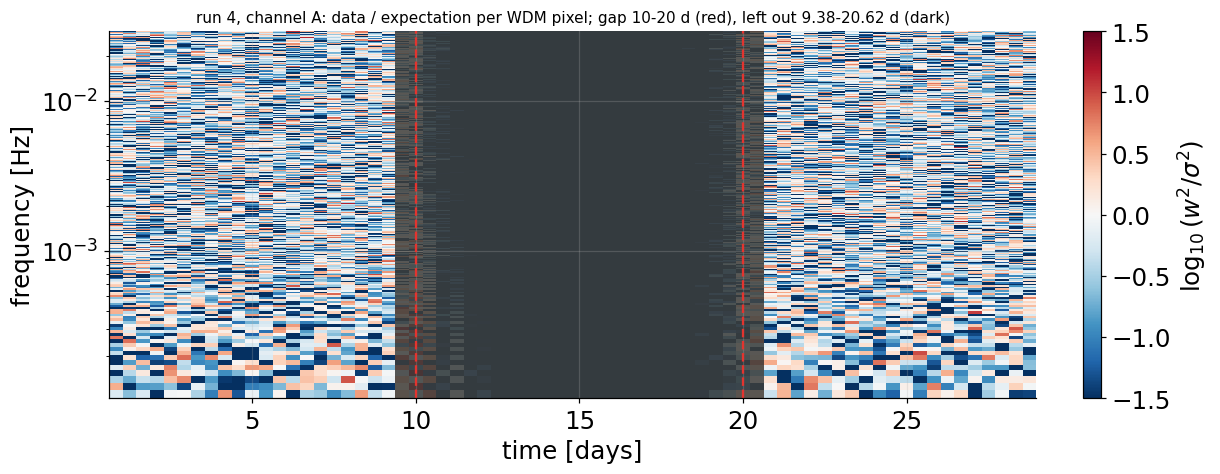

In [2]:
data2, inj = I.load_or_simulate('sky', 'run2')
like2, post2 = I.build_posterior(data2)
data3, _ = I.load_or_simulate('sky', 'run4', CFG3)
like3, post3 = I.build_posterior(data3, CFG3)
mask = I.gap_time_mask(data3, CFG3)
dT = data3.Nf * data3.dt
off = np.flatnonzero(~mask)
gap_lo, gap_hi = (data3.times[off[0]] - dT / 2) / DAY, (data3.times[off[-1]] + dT / 2) / DAY
x2, dt, t0 = I.load_timeseries('run2'); x3, _, _ = I.load_timeseries('run4')
t = t0 + np.arange(x3.shape[1]) * dt
g = (t >= GAP[0] * DAY) & (t < GAP[1] * DAY)
print(f"run 4 series = run 2 series outside the gap: {np.array_equal(x3[:, ~g], x2[:, ~g])}; zero inside: {np.all(x3[:, g] == 0)}")
print(f"left out: time pixels {off.tolist()} = {gap_lo:.2f}-{gap_hi:.2f} d ({(gap_hi - gap_lo) * 24:.0f} h)")
print(f"likelihood blocks: run 2 {len(like2.times)}, run 4 {len(like3.times)}; "
      f"pixels used: run 2 {like2.npixels}, run 4 {like3.npixels} ({100 * (1 - like3.npixels / like2.npixels):.1f}% fewer)")

# per-pixel data / expectation at the injection (true amplitude), channel A, masked columns shaded
names_w = [p.name for p in _sampled(post2.psd_params)]
theta_true = np.array([p.value for p in _sampled(post2.psd_params)], float)
theta_true[names_w.index('amp')] = amp_true
f = like2.eval_freqs
from bahamas.psd_strain import psd_galaxy as gal, psd_noise as noise
from bahamas.wavelet.sampler import _fill
vals = _fill(post2.psd_params, jnp.asarray(theta_true))
per_pixel = lambda s: np.asarray(jnp.reshape(s, (like2.npix, -1)) @ like2._weights)
Sg = per_pixel(gal.galactic_foreground(f, vals['galactic_DWD_time'], gen2=False))
Sn = per_pixel(noise.noise(f, vals['instr_noise'], tdi=0, gen2=False))
ti = like2.time_index
sig2 = (np.asarray(inj.P(data3.times[ti], 0))[:, None] * Sg[None] + Sn[None]) / (2 * data3.dt)
z = data3.w[0][ti][:, like2.pixels] ** 2 / sig2
te = np.append(data3.times[ti] - dT / 2, data3.times[ti][-1] + dT / 2) / DAY
fp = data3.freqs[like2.pixels]; dF = fp[1] - fp[0]
fe = np.append(fp - dF / 2, fp[-1] + dF / 2)
fig, ax = plt.subplots(figsize=(11, 4.2), constrained_layout=True)
from matplotlib.colors import TwoSlopeNorm
m = ax.pcolormesh(te, fe, np.log10(z).T, cmap='RdBu_r', norm=TwoSlopeNorm(vcenter=0, vmin=-1.5, vmax=1.5),
                  shading='flat', rasterized=True)
ax.axvspan(gap_lo, gap_hi, color='#3d3d3a', alpha=0.85, lw=0, label='left out of the likelihood')
for e in GAP:
    ax.axvline(e, color='#e3342f', ls='--', lw=1.5)
ax.set_yscale('log'); ax.set_xlabel('time [days]'); ax.set_ylabel('frequency [Hz]')
ax.set_title(f'run 4, channel A: data / expectation per WDM pixel; gap {GAP[0]:g}-{GAP[1]:g} d (red), '
             f'left out {gap_lo:.2f}-{gap_hi:.2f} d (dark)', fontsize=10)
fig.colorbar(m, ax=ax, label=r'$\log_{10}(w^2/\sigma^2)$')
fig.savefig(OUT / 'data_gap_mask.png', dpi=140)

## 2. Sampling and convergence (run 4)

In [3]:
res_path = OUT / 'chains.npz'
if RERUN or not res_path.exists():
    I.run('sky', 'run4', config=CFG3)
r3 = dict(np.load(res_path, allow_pickle=True))
r2 = dict(np.load(HERE / 'outputs' / 'run2' / 'chains.npz', allow_pickle=True))
nsteps, nw = int(r3['nsteps']), int(r3['nwalkers'])
print(f"runtime {float(r3['runtime_s']) / 60:.1f} min, {nsteps} steps x {nw} walkers (cold chain); acceptance "
      f"{np.mean(r3['acceptance_fraction']):.3f}, RJ acceptance {np.mean(r3['rj_acceptance_fraction']):.3f}\n")
D.report(r3, post3, np.array([5., 15., 25.]) * DAY)
print()
for c in CH:
    for lab, r in (('run 2 (no gap)', r2), ('run 4 (gap)   ', r3)):
        K, p = r[f'mod_{c}_bayes_K'], r[f'mod_{c}_bayes_posterior']
        print(f"{c} {lab}: " + ' '.join(f'p(K={k})={q:.3f}' for k, q in zip(K, p) if q > 1e-3))

runtime 25.5 min, 6000 steps x 32 walkers (cold chain); acceptance 0.092, RJ acceptance 0.010



        quantity  tau_acf tau_batch      ESS  nsteps/tau
           alpha      1.7       5.5    35043      1095.1
             amp      1.7       2.5    77999      2437.5
           fknee      1.5       2.6    73762      2305.1
             fr1      1.7       5.5    35213      1100.4
             fr2      1.6       4.2    45833      1432.3
               A      1.7       4.9    39125      1222.7
               P      1.5       2.5    75506      2359.6
         level_E      1.7       3.1    61370      1917.8
             K_A      1.8       3.3    58283      1821.3
             K_E      1.9       4.5    42791      1337.2
           log L      2.2       2.7    71482      2233.8
        P_A(5 d)      1.6       4.4    43280      1352.5
       P_A(15 d)      1.6       5.0    38320      1197.5
       P_A(25 d)      1.6       4.5    42441      1326.3
        P_E(5 d)      1.6       4.4    43896      1371.7
       P_E(15 d)      1.7       4.4    43436      1357.4
       P_E(25 d)      1.6      

## 3. Spectral parameters: gap vs no gap

param       truth |   no gap: median, 90% width |   gap: median, 90% width | width gap/no gap | shift / sigma(no gap)
alpha       1.800 |       1.8324       0.2002 |       1.8242     0.2537 |            1.268 | -0.14
amp               |     -43.4010       0.2472 |     -43.4015     0.2626 |            1.063 | -0.01
fknee      -2.177 |      -2.1785       0.0061 |      -2.1790     0.0074 |            1.213 | -0.25
fr1        -2.429 |      -2.4189       0.0246 |      -2.4204     0.0324 |            1.316 | -0.20
fr2        -3.488 |      -3.5451       0.2364 |      -3.5599     0.2633 |            1.114 | -0.21
A           2.400 |       2.4427       0.1181 |       2.4603     0.1550 |            1.312 | +0.48
P           7.900 |       7.9040       0.0433 |       7.9056     0.0539 |            1.246 | +0.12
level_E           |       1.1430       0.4995 |       1.0972     0.7350 |            1.472 | -0.31


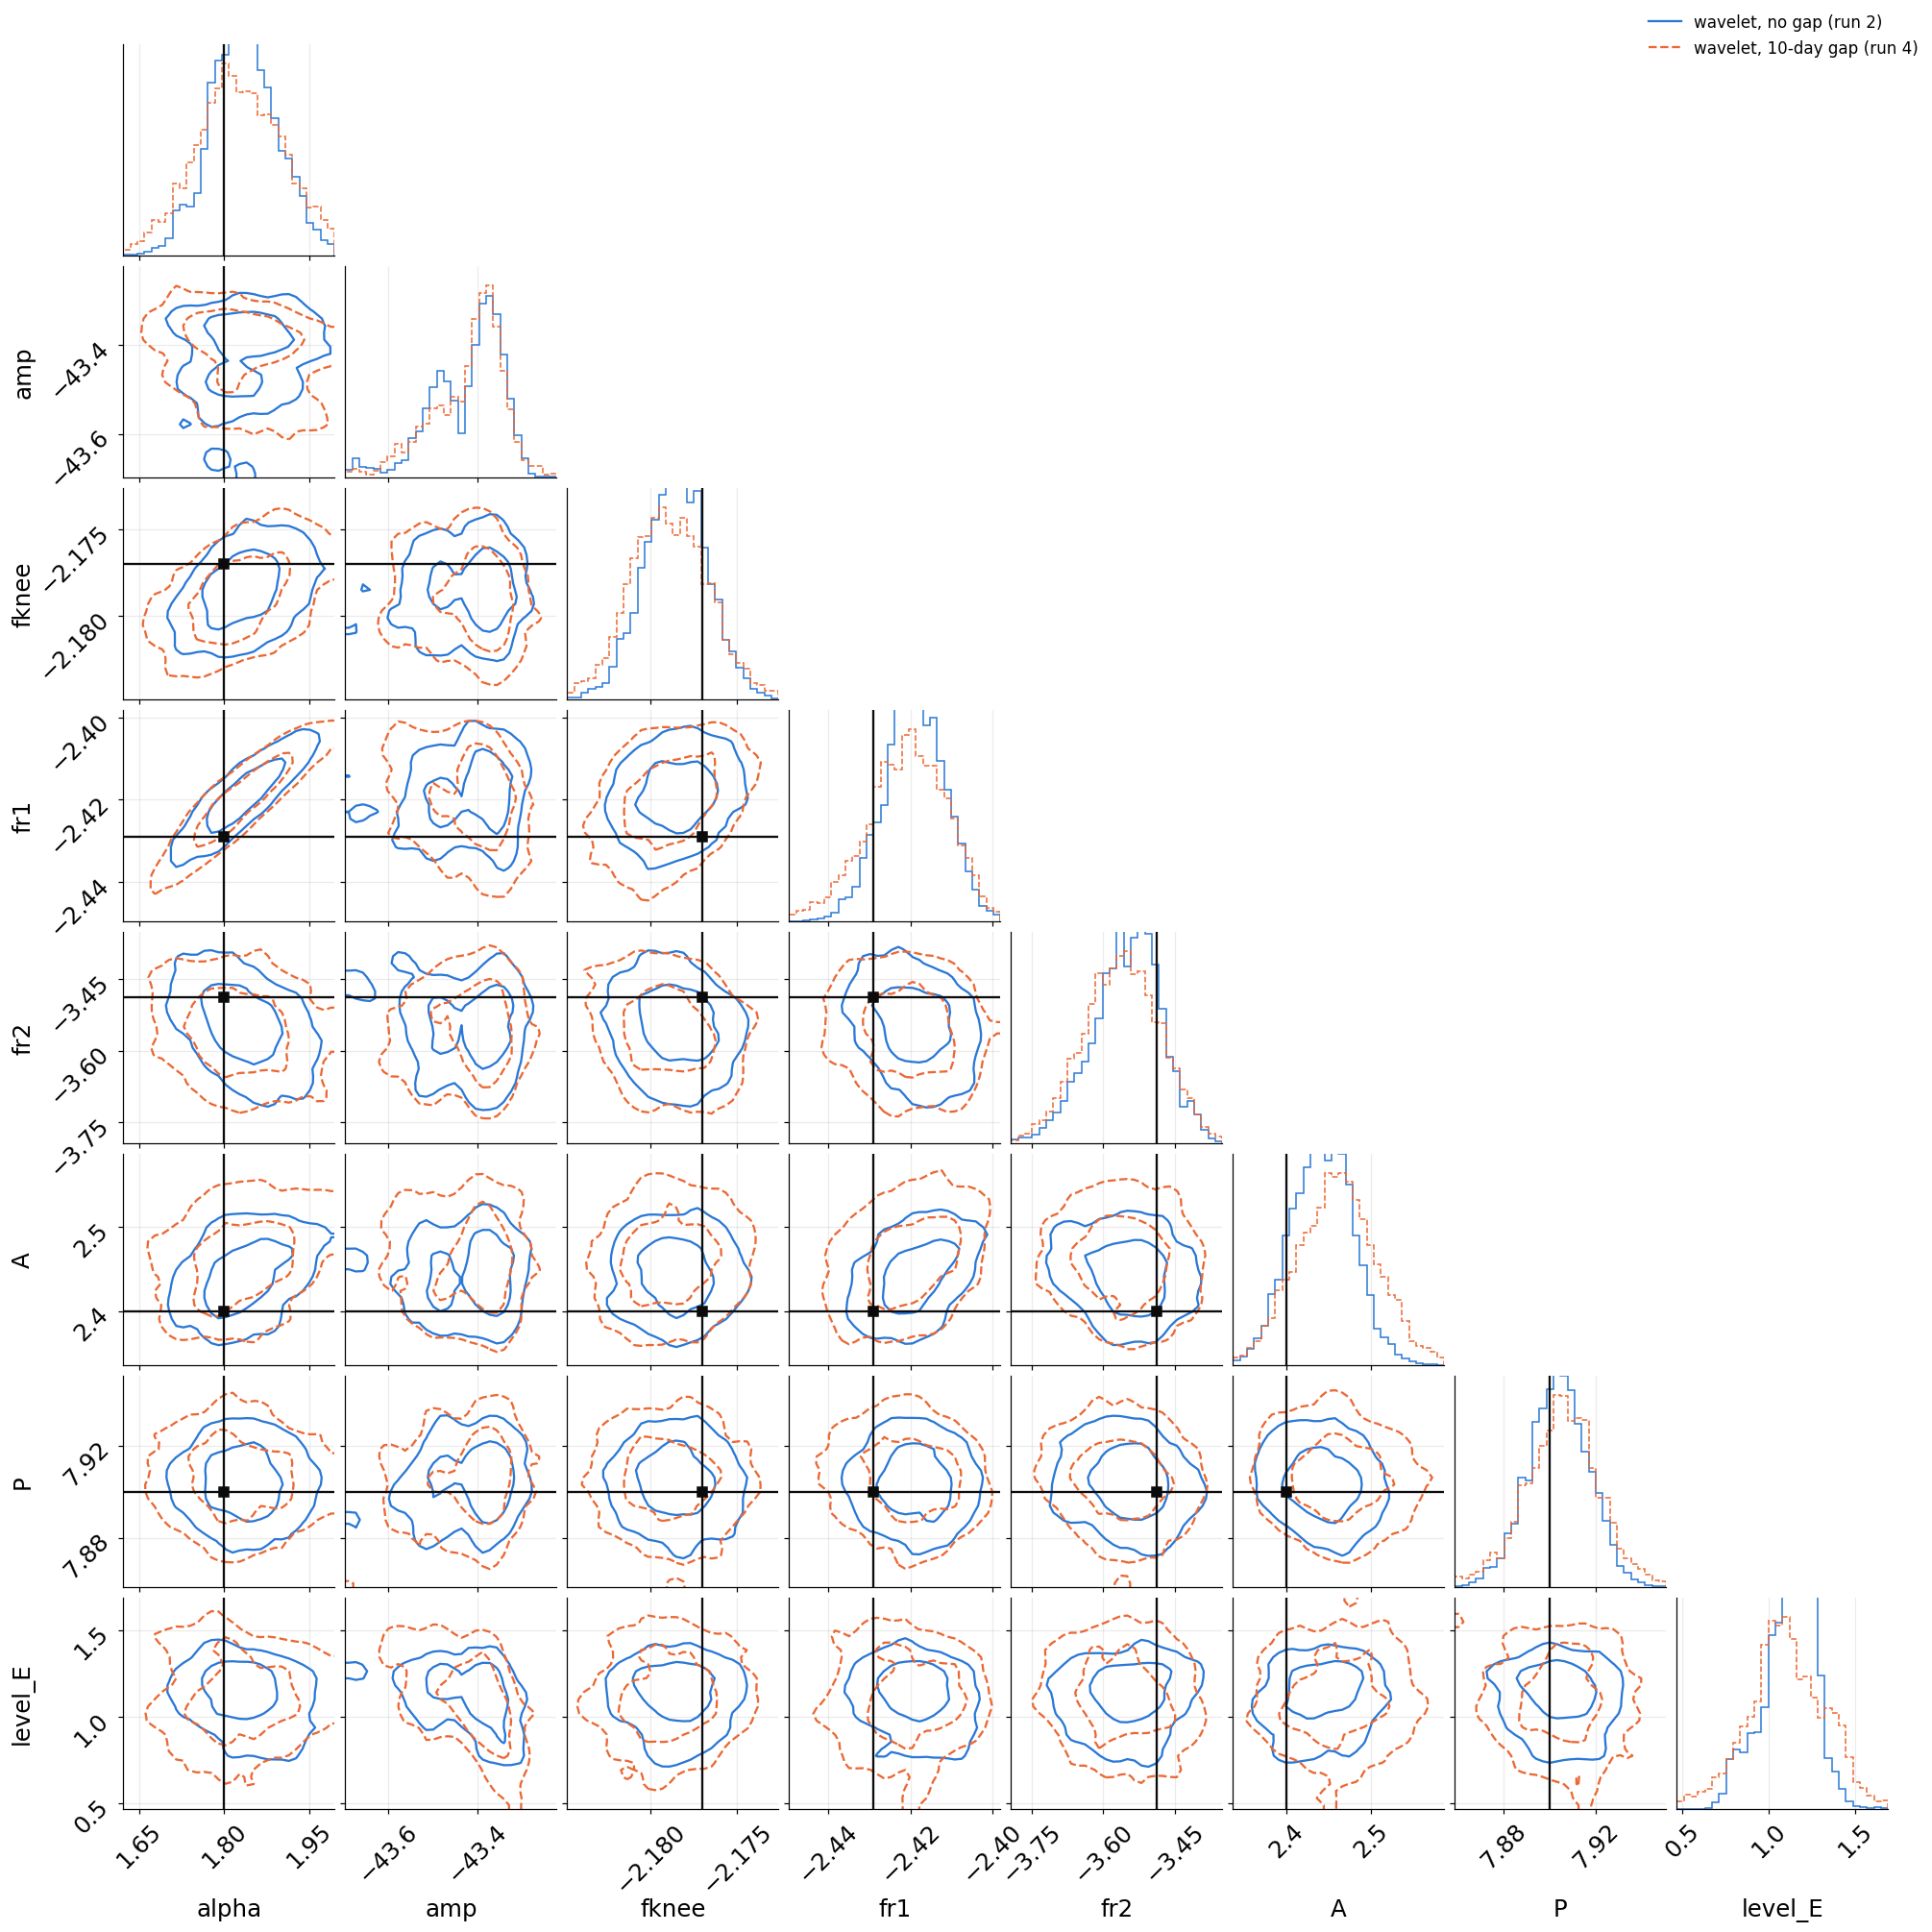

In [4]:
shared = ['alpha', 'amp', 'fknee', 'fr1', 'fr2', 'A', 'P', 'level_E']
names = [str(n).split(':')[-1] for n in r2['psd_names']]
ch2 = np.column_stack([r2['psd_chain'][:, names.index(k)] for k in shared])
ch3 = np.column_stack([r3['psd_chain'][:, names.index(k)] for k in shared])
truth_src = {p['name']: p['injected'] for s in I.og_sources().values() for p in s}
truths = [truth_src.get(k) if k not in ('amp', 'level_E') else None for k in shared]
rng_ = [tuple(np.percentile(np.r_[ch2[:, i], ch3[:, i]], [0.2, 99.8])) for i in range(len(shared))]
def kw(ls='-'):
    return dict(range=rng_, bins=30, smooth=1.0, plot_datapoints=False, plot_density=False, levels=(0.5, 0.9),
                max_n_ticks=3, labelpad=0.12, hist_kwargs={'density': True, 'linestyle': ls}, contour_kwargs={'linestyles': ls})
fig = corner.corner(ch2, labels=shared, color=C_NOGAP, **kw())
corner.corner(ch3, fig=fig, color=C_GAP, truths=truths, truth_color=C_TRUTH, **kw('--'))
fig.legend(handles=[plt.Line2D([], [], color=C_NOGAP, label='wavelet, no gap (run 2)'),
                    plt.Line2D([], [], color=C_GAP, ls='--', label='wavelet, 10-day gap (run 4)')], loc='upper right', fontsize=11)
fig.savefig(OUT / 'corner_gap_vs_nogap.png', dpi=110, bbox_inches='tight')

print(f"{'param':8s} {'truth':>8s} | {'no gap: median, 90% width':>27s} | {'gap: median, 90% width':>24s} | width gap/no gap | shift / sigma(no gap)")
for i, k in enumerate(shared):
    q2, q3 = np.percentile(ch2[:, i], [5, 50, 95]), np.percentile(ch3[:, i], [5, 50, 95])
    tr = '' if truths[i] is None else f'{truths[i]:8.3f}'
    print(f"{k:8s} {tr:>8s} | {q2[1]:12.4f} {q2[2] - q2[0]:12.4f} | {q3[1]:12.4f} {q3[2] - q3[0]:10.4f} | "
          f"{(q3[2] - q3[0]) / (q2[2] - q2[0]):16.3f} | {(q3[1] - q2[1]) / ch2[:, i].std():+.2f}")

## 4. The modulation: recovered galactic brightness, gap vs no gap

For each of 1000 posterior samples: (its amplitude × its spectral shape × its $P_c(t)$) / (the injected ones), then the
median and the 50% / 90% bands over the samples at each time. 0 on the plot = recovered equals injected. The dark band
is the time left out of the run-4 likelihood; there the run-4 curve is an interpolation by the atoms.

A:
   no gap (run 2)  90% width: 7.3% away from the gap, up to 5.9% within 1 d of it;  median offset +1.5%;  truth inside 90%: 90% of the span, 100% near the gap
   gap (run 4)     90% width: 7.6% away from the gap, up to 14.6% within 1 d of it;  median offset +1.9%;  truth inside 90%: 98% of the span, 100% near the gap
E:
   no gap (run 2)  90% width: 6.7% away from the gap, up to 5.4% within 1 d of it;  median offset -1.3%;  truth inside 90%: 100% of the span, 100% near the gap
   gap (run 4)     90% width: 7.0% away from the gap, up to 13.1% within 1 d of it;  median offset -1.5%;  truth inside 90%: 100% of the span, 100% near the gap


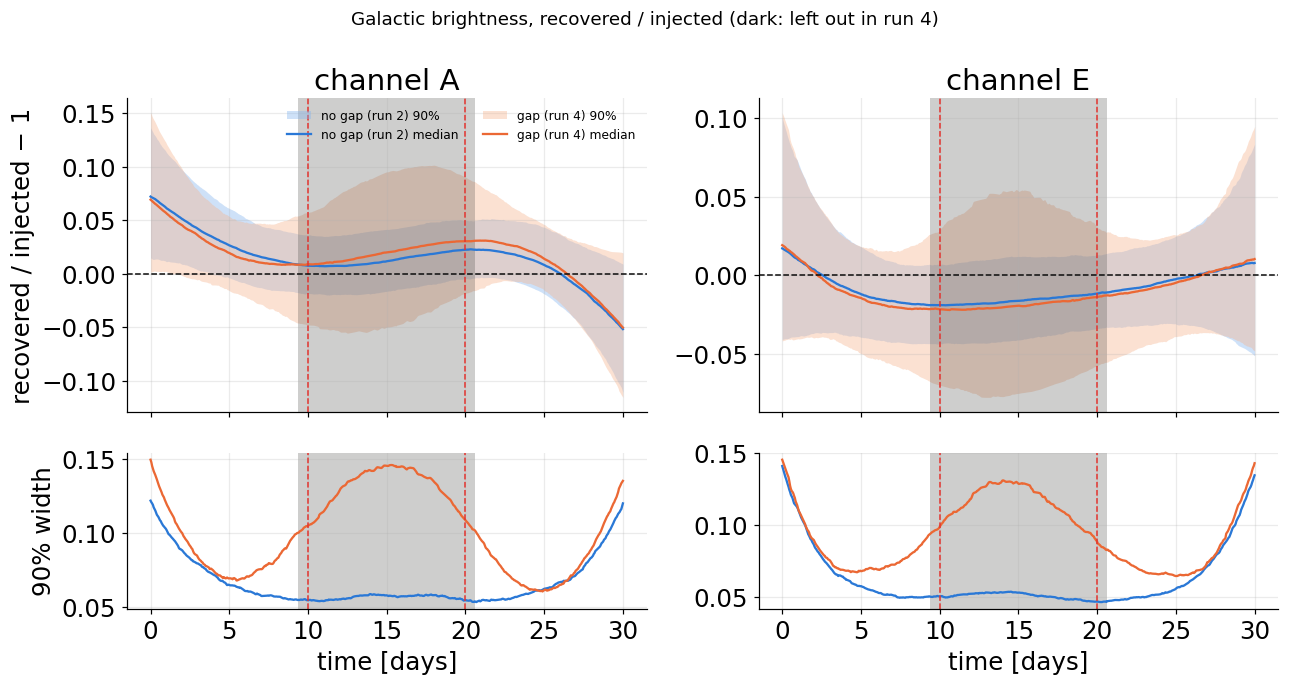

In [5]:
t_fine = np.linspace(0, data2.Nt * dT, 600)
P_true = np.stack([np.asarray(power_modulation(I.sky_params(), t_fine, c)) for c in (0, 1)])
theta_inj = np.array([p.value for p in _sampled(post2.psd_params)], float)          # amp = amp_ref
Sg0, Sn0, _ = post2.spectra(jnp.asarray(theta_inj)); Sg0, Sn0 = np.asarray(Sg0), np.asarray(Sn0)
ok = Sg0 > 1e-3 * Sg0.max()
W = np.stack([np.where(ok, np.asarray(like2.nu) * (Sg0 / (Sg0 + Sn0[c])) ** 2, 0.) for c in (0, 1)])
W /= W.sum(1, keepdims=True)
spec_batch = jax.jit(jax.vmap(lambda th: post2.spectra(th)[0]))

def brightness(r, post):
    # (ndraw, 2, nt): amplitude x shape x P_c relative to the injection, for 1000 posterior draws
    idx = np.random.default_rng(0).choice(len(r['psd_chain']), size=1000, replace=False)
    P = 10 ** (amp_ref - amp_true) * modulation_draws(post, r, t_fine, nsamples=1000, seed=0)   # 10^(amp - amp_true) P_c
    th = np.array(r['psd_chain'][idx], float); th[:, names_w.index('amp')] = theta_inj[names_w.index('amp')]
    R = np.where(ok, np.asarray(spec_batch(jnp.asarray(th))) / np.where(ok, Sg0, 1.), 0.) @ W.T
    return P * R[:, :, None] / P_true[None]

B = {'no gap (run 2)': brightness(r2, post2), 'gap (run 4)': brightness(r3, post3)}
td = t_fine / DAY
t_lo, t_hi = float(like2.times[0]) / DAY, float(like2.times[-1]) / DAY
inside = (td >= t_lo) & (td <= t_hi)
near = (td >= gap_lo - 1) & (td <= gap_hi + 1)
far = inside & ~((td >= gap_lo - 4) & (td <= gap_hi + 4))
fig, axes = plt.subplots(2, 2, figsize=(12, 6.4), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
summary = {}
for i, c in enumerate(CH):
    ax, axw = axes[:, i]
    summary[c] = {}
    for (lab, b), cl, cd in zip(B.items(), (C_NOGAP_L, C_GAP_L), (C_NOGAP, C_GAP)):
        q = np.percentile(b[:, i], [5, 25, 50, 75, 95], axis=0)
        ax.fill_between(td, q[0] - 1, q[4] - 1, color=cl, alpha=0.4, lw=0, label=f'{lab} 90%')
        ax.plot(td, q[2] - 1, color=cd, label=f'{lab} median')
        axw.plot(td, q[4] - q[0], color=cd, label=lab)
        wdt = q[4] - q[0]
        summary[c][lab] = dict(w_far=np.median(wdt[far]), w_near=np.max(wdt[near]), off=np.median(q[2][inside]) - 1,
                               cov=np.mean(((q[0] <= 1) & (1 <= q[4]))[inside]), cov_near=np.mean(((q[0] <= 1) & (1 <= q[4]))[near]))
    for a in (ax, axw):
        a.axvspan(gap_lo, gap_hi, color='#3d3d3a', alpha=0.25, lw=0)
        for e in GAP:
            a.axvline(e, color='#e3342f', ls='--', lw=1)
    ax.axhline(0, color=C_TRUTH, ls='--', lw=1)
    ax.set_title(f'channel {c}')
    axw.set_xlabel('time [days]')
    print(f"{c}:")
    for lab, s in summary[c].items():
        print(f"   {lab:15s} 90% width: {100 * s['w_far']:.1f}% away from the gap, up to {100 * s['w_near']:.1f}% within 1 d of it;"
              f"  median offset {100 * s['off']:+.1f}%;  truth inside 90%: {100 * s['cov']:.0f}% of the span, "
              f"{100 * s['cov_near']:.0f}% near the gap")
axes[0, 0].legend(fontsize=8, ncol=2)
axes[1, 0].set_ylabel('90% width')
axes[0, 0].set_ylabel('recovered / injected − 1')
fig.suptitle('Galactic brightness, recovered / injected (dark: left out in run 4)', fontsize=12)
fig.tight_layout()
fig.savefig(OUT / 'modulation_gap_vs_nogap.png', dpi=150)

In [6]:
# Band widths at fixed days, inside the left-out span, and over the kept data away from the window ends
ingap = (td >= gap_lo) & (td <= gap_hi)
kept = inside & ~ingap & (td > 3) & (td < 27)
for i, c in enumerate(CH):
    print(c)
    for lab, b in B.items():
        q = np.percentile(b[:, i], [5, 50, 95], axis=0); w = q[2] - q[0]
        at = [100 * np.interp(d, td, w) for d in (5, 10, 15, 20, 25)]
        print(f"   {lab:15s} 90% width at 5/10/15/20/25 d: " + ' / '.join(f'{v:.1f}' for v in at)
              + f" %;  inside the gap: mean {100 * w[ingap].mean():.1f}%, max {100 * w[ingap].max():.1f}%;  kept data 3-27 d: "
              f"mean {100 * w[kept].mean():.1f}%;  median offset in the gap {100 * (np.median(q[1][ingap]) - 1):+.1f}%;  "
              f"truth inside 90% in the gap {100 * np.mean(((q[0] <= 1) & (1 <= q[2]))[ingap]):.0f}%")

A
   no gap (run 2)  90% width at 5/10/15/20/25 d: 6.5 / 5.5 / 5.8 / 5.5 / 6.2 %;  inside the gap: mean 5.7%, max 5.9%;  kept data 3-27 d: mean 6.1%;  median offset in the gap +1.2%;  truth inside 90% in the gap 100%
   gap (run 4)     90% width at 5/10/15/20/25 d: 6.9 / 10.5 / 14.5 / 10.9 / 6.2 %;  inside the gap: mean 12.9%, max 14.6%;  kept data 3-27 d: mean 7.5%;  median offset in the gap +2.0%;  truth inside 90% in the gap 100%
E
   no gap (run 2)  90% width at 5/10/15/20/25 d: 5.8 / 5.0 / 5.3 / 4.7 / 5.6 %;  inside the gap: mean 5.1%, max 5.4%;  kept data 3-27 d: mean 5.5%;  median offset in the gap -1.6%;  truth inside 90% in the gap 100%
   gap (run 4)     90% width at 5/10/15/20/25 d: 6.8 / 9.9 / 12.9 / 8.8 / 6.5 %;  inside the gap: mean 11.3%, max 13.1%;  kept data 3-27 d: mean 7.2%;  median offset in the gap -1.9%;  truth inside 90% in the gap 100%


### Recovered modulation, data-covered times only

The recovered $P_c(t)$ of run 4 against the injected envelope $M_c^2(t)$, drawn only where the likelihood has data: the
left-out span is blank. Each sample's $P_c(t)$ is put on the injected scale with its amplitude and spectral shape
(recovered brightness / injected brightness × $M_c^2(t)$), so the dashed curve is the truth.

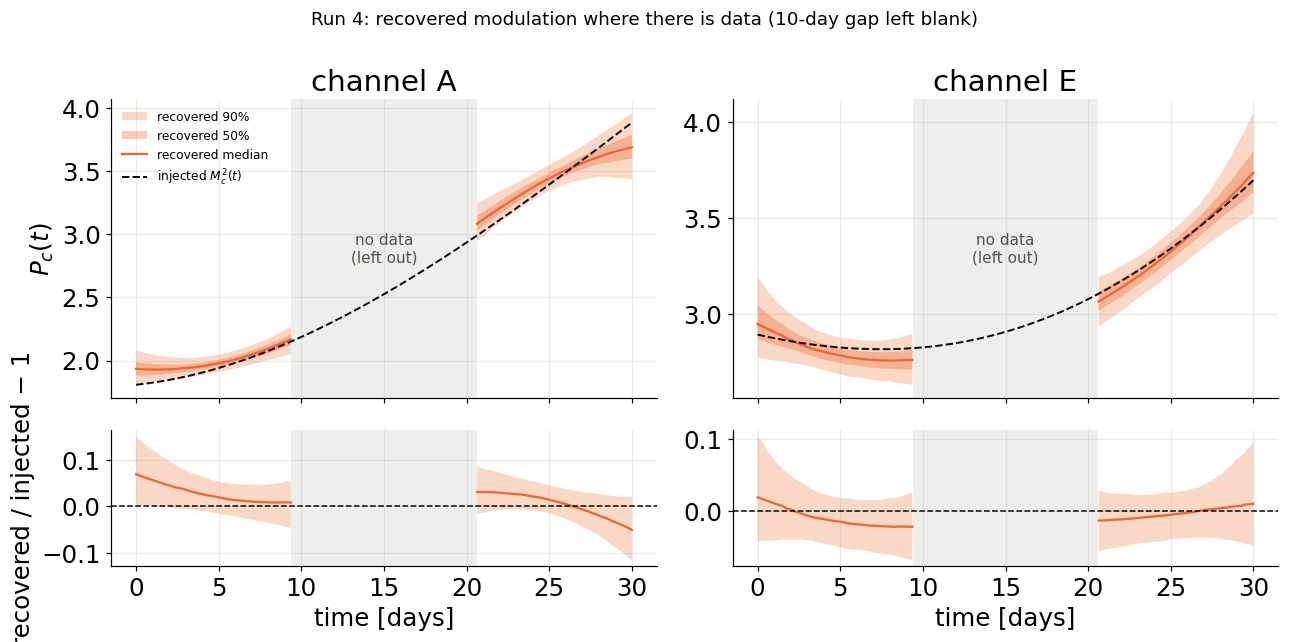

In [7]:
b4 = B['gap (run 4)']                                    # recovered / injected brightness, (ndraw, 2, nt)
has_data = ~((td >= gap_lo) & (td <= gap_hi))
fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True, gridspec_kw={'height_ratios': [2.2, 1]})
for i, c in enumerate(CH):
    ax, axr = axes[:, i]
    q = np.percentile(b4[:, i] * P_true[i], [5, 25, 50, 75, 95], axis=0)
    q = np.where(has_data, q, np.nan)                       # nothing drawn in the gap
    ax.fill_between(td, q[0], q[4], color=C_GAP_L, alpha=0.5, lw=0, label='recovered 90%')
    ax.fill_between(td, q[1], q[3], color=C_GAP, alpha=0.35, lw=0, label='recovered 50%')
    ax.plot(td, q[2], color=C_GAP, label='recovered median')
    ax.plot(td, P_true[i], color=C_TRUTH, ls='--', lw=1.3, label=r'injected $M_c^2(t)$')
    r = np.where(has_data, np.percentile(b4[:, i], [5, 50, 95], axis=0), np.nan)
    axr.fill_between(td, r[0] - 1, r[2] - 1, color=C_GAP_L, alpha=0.5, lw=0)
    axr.plot(td, r[1] - 1, color=C_GAP)
    axr.axhline(0, color=C_TRUTH, ls='--', lw=1)
    for a in (ax, axr):
        a.axvspan(gap_lo, gap_hi, color='#eeeeec', lw=0, zorder=0)
    ax.text((gap_lo + gap_hi) / 2, 0.5, 'no data\n(left out)', transform=ax.get_xaxis_transform(), ha='center',
            va='center', color=C_MUTED, fontsize=10)
    ax.set_title(f'channel {c}')
    axr.set_xlabel('time [days]')
axes[0, 0].set_ylabel(r'$P_c(t)$')
axes[1, 0].set_ylabel('recovered / injected − 1')
axes[0, 0].legend(fontsize=8, loc='upper left')
fig.suptitle('Run 4: recovered modulation where there is data (10-day gap left blank)', fontsize=12)
fig.tight_layout()
fig.savefig(OUT / 'modulation_recovered.png', dpi=150)

### Shape only

Each sample's $P_c(t)$ divided by its own mean over the analysed span (amplitude and spectrum drop out).

A shape, no gap (run 2): median 90% width 4.3%, truth inside 100%
A shape, gap (run 4): median 90% width 6.9%, truth inside 100%
E shape, no gap (run 2): median 90% width 3.9%, truth inside 100%
E shape, gap (run 4): median 90% width 6.8%, truth inside 100%


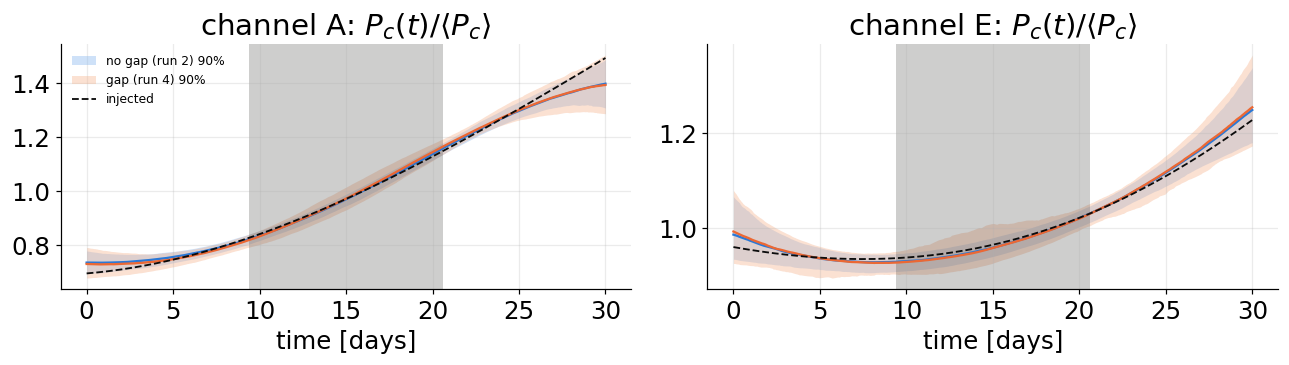

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharex=True)
S_true = P_true / P_true[:, inside].mean(1, keepdims=True)
for i, (ax, c) in enumerate(zip(axes, CH)):
    for (lab, r, post), cl, cd in zip([('no gap (run 2)', r2, post2), ('gap (run 4)', r3, post3)], (C_NOGAP_L, C_GAP_L), (C_NOGAP, C_GAP)):
        Pd = modulation_draws(post, r, t_fine, nsamples=1000, seed=0)[:, i]
        S = Pd / Pd[:, inside].mean(1, keepdims=True)
        q = np.percentile(S, [5, 50, 95], axis=0)
        ax.fill_between(td, q[0], q[2], color=cl, alpha=0.4, lw=0, label=f'{lab} 90%')
        ax.plot(td, q[1], color=cd)
        print(f"{c} shape, {lab}: median 90% width {100 * np.median((q[2] - q[0])[inside]):.1f}%, "
              f"truth inside {100 * np.mean(((q[0] <= S_true[i]) & (S_true[i] <= q[2]))[inside]):.0f}%")
    ax.plot(td, S_true[i], color=C_TRUTH, ls='--', lw=1.2, label='injected')
    ax.axvspan(gap_lo, gap_hi, color='#3d3d3a', alpha=0.25, lw=0)
    ax.set_title(f'channel {c}: $P_c(t)/\\langle P_c\\rangle$'); ax.set_xlabel('time [days]')
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / 'shape_gap_vs_nogap.png', dpi=150)

## 5. Summary

The numbers above are collected in [reports/WAVELET_INJECTION_RUN4.md](../../reports/WAVELET_INJECTION_RUN4.md).